In [1]:
!pip install yfinance pandas



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


Market News for particular stock

In [2]:
import yfinance as yf
import pandas as pd

stock = yf.Ticker("RELIANCE.NS")
news_items = stock.news

news_data = []
for item in news_items[:10]:  # get latest 10
    content = item.get('content', {})
    title = content.get('title', 'No title')
    url = content.get('canonicalUrl', {}).get('url', 'No link')
    provider = content.get('provider', {}).get('displayName', 'Unknown')
    pubDate = content.get('pubDate', 'Unknown')

    news_data.append({
        'title': title,
        'url': url,
        'provider': provider,
        'pubDate': pubDate
    })

# Convert to DataFrame
df_news = pd.DataFrame(news_data)
print(df_news)


                                               title  \
0  Amazon to invest over $35 billion in India on ...   
1  Reliance-Disney's JioHotstar to invest $444 mi...   
2  India’s Reliance Retail completes consumer bus...   
3  The Bull Case For Digital Realty Trust (DLR) C...   
4  How the Narrative for Reliance Is Evolving Ami...   
5  How Brookfield’s (TSX:BN) $11 Billion AI Data ...   
6  Reliance plans $11bn AI data centre in Visakha...   
7  Reliance Industries, JV partners to invest $11...   
8  Reliance stops buying Russian crude at major r...   
9  Why Analysts See Reliance Industries Shifting ...   

                                                 url                provider  \
0  https://finance.yahoo.com/news/amazon-invest-o...                 Reuters   
1  https://finance.yahoo.com/news/reliance-disney...                 Reuters   
2  https://www.retail-insight-network.com/news/in...  Retail Insight Network   
3  https://finance.yahoo.com/news/bull-case-digit...         Si

In [3]:
import yfinance as yf
import pandas as pd

stock = yf.Ticker("RELIANCE.NS")
news_items = stock.news

# Extract relevant fields safely
news_data = []
for item in news_items[:10]:
    content = item.get('content', {})
    news_data.append({
        'title': content.get('title', 'No title'),
        'url': content.get('canonicalUrl', {}).get('url', 'No link'),
        'provider': content.get('provider', {}).get('displayName', 'Unknown'),
        'pubDate': content.get('pubDate', 'Unknown')
    })

# Convert to DataFrame
df_news = pd.DataFrame(news_data)

# Now you can safely print columns
print(df_news[['title', 'url', 'provider', 'pubDate']])


                                               title  \
0  Amazon to invest over $35 billion in India on ...   
1  Reliance-Disney's JioHotstar to invest $444 mi...   
2  India’s Reliance Retail completes consumer bus...   
3  The Bull Case For Digital Realty Trust (DLR) C...   
4  How the Narrative for Reliance Is Evolving Ami...   
5  How Brookfield’s (TSX:BN) $11 Billion AI Data ...   
6  Reliance plans $11bn AI data centre in Visakha...   
7  Reliance Industries, JV partners to invest $11...   
8  Reliance stops buying Russian crude at major r...   
9  Why Analysts See Reliance Industries Shifting ...   

                                                 url                provider  \
0  https://finance.yahoo.com/news/amazon-invest-o...                 Reuters   
1  https://finance.yahoo.com/news/reliance-disney...                 Reuters   
2  https://www.retail-insight-network.com/news/in...  Retail Insight Network   
3  https://finance.yahoo.com/news/bull-case-digit...         Si

Day2

In [4]:
!pip install textblob
!python -m textblob.download_corpora



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: pip install --upgrade pip
[nltk_data] Downloading package brown to /home/fa064034/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/fa064034/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/fa064034/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/fa064034/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package conll2000 to
[nltk_data]     /home/fa064034/nltk_data...
[nltk_data]   Package conll2000 is already up-to-date!
[nltk_data] Downloading package movie_reviews to
[nltk_data]     /home/fa064034/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!


Sentiment Anlysis news positive , negative or neutral

In [5]:
from textblob import TextBlob
import pandas as pd

# Assuming df_news from Day 1
# df_news columns: ['title', 'url', 'provider', 'pubDate']

def get_sentiment(text):
    analysis = TextBlob(text)
    polarity = analysis.sentiment.polarity  # ranges from -1 to +1
    if polarity > 0.05:
        label = "Positive"
    elif polarity < -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    return polarity, label

# Apply sentiment scoring
df_news[['sentiment_score', 'sentiment_label']] = df_news['title'].apply(
    lambda x: pd.Series(get_sentiment(x))
)

# View results
print(df_news[['title', 'sentiment_score', 'sentiment_label']])


                                               title  sentiment_score  \
0  Amazon to invest over $35 billion in India on ...         0.000000   
1  Reliance-Disney's JioHotstar to invest $444 mi...         0.000000   
2  India’s Reliance Retail completes consumer bus...         0.000000   
3  The Bull Case For Digital Realty Trust (DLR) C...        -0.025000   
4  How the Narrative for Reliance Is Evolving Ami...         0.136364   
5  How Brookfield’s (TSX:BN) $11 Billion AI Data ...         0.000000   
6  Reliance plans $11bn AI data centre in Visakha...         0.000000   
7  Reliance Industries, JV partners to invest $11...         0.000000   
8  Reliance stops buying Russian crude at major r...        -0.212500   
9  Why Analysts See Reliance Industries Shifting ...         0.000000   

  sentiment_label  
0         Neutral  
1         Neutral  
2         Neutral  
3         Neutral  
4        Positive  
5         Neutral  
6         Neutral  
7         Neutral  
8        Negativ

In [6]:
sentiment_summary = df_news['sentiment_label'].value_counts(normalize=True) * 100
print(sentiment_summary)


sentiment_label
Neutral     80.0
Positive    10.0
Negative    10.0
Name: proportion, dtype: float64


In [7]:
import yfinance as yf
import pandas as pd
from textblob import TextBlob

def get_stock_sentiment(ticker, n=10):
    """
    Fetch latest news headlines for a stock and calculate sentiment.
    
    Args:
        ticker (str): Stock ticker with .NS (NSE) or .BO (BSE)
        n (int): Number of latest news items to fetch
    
    Returns:
        pd.DataFrame: DataFrame with columns:
                      ['title', 'url', 'provider', 'pubDate', 'sentiment_score', 'sentiment_label']
    """
    stock = yf.Ticker(ticker)
    news_items = stock.news[:n]
    
    news_data = []
    for item in news_items:
        content = item.get('content', {})
        title = content.get('title', 'No title')
        url = content.get('canonicalUrl', {}).get('url', 'No link')
        provider = content.get('provider', {}).get('displayName', 'Unknown')
        pubDate = content.get('pubDate', 'Unknown')
        
        # Sentiment scoring
        analysis = TextBlob(title)
        polarity = analysis.sentiment.polarity
        if polarity > 0.05:
            label = "Positive"
        elif polarity < -0.05:
            label = "Negative"
        else:
            label = "Neutral"
        
        news_data.append({
            'title': title,
            'url': url,
            'provider': provider,
            'pubDate': pubDate,
            'sentiment_score': polarity,
            'sentiment_label': label
        })
    
    df = pd.DataFrame(news_data)
    return df


In [8]:
df_reliance = get_stock_sentiment("RELIANCE.NS", n=10)
print(df_reliance[['title', 'sentiment_score', 'sentiment_label']])


                                               title  sentiment_score  \
0  Amazon to invest over $35 billion in India on ...         0.000000   
1  Reliance-Disney's JioHotstar to invest $444 mi...         0.000000   
2  India’s Reliance Retail completes consumer bus...         0.000000   
3  The Bull Case For Digital Realty Trust (DLR) C...        -0.025000   
4  How the Narrative for Reliance Is Evolving Ami...         0.136364   
5  How Brookfield’s (TSX:BN) $11 Billion AI Data ...         0.000000   
6  Reliance plans $11bn AI data centre in Visakha...         0.000000   
7  Reliance Industries, JV partners to invest $11...         0.000000   
8  Reliance stops buying Russian crude at major r...        -0.212500   
9  Why Analysts See Reliance Industries Shifting ...         0.000000   

  sentiment_label  
0         Neutral  
1         Neutral  
2         Neutral  
3         Neutral  
4        Positive  
5         Neutral  
6         Neutral  
7         Neutral  
8        Negativ

Day4

In [9]:
!pip install yfinance pandas matplotlib



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [10]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob

# Reuse the get_stock_sentiment function from Day 2
def get_stock_sentiment(ticker, n=50):
    stock = yf.Ticker(ticker)
    news_items = stock.news[:n]
    
    news_data = []
    for item in news_items:
        content = item.get('content', {})
        title = content.get('title', 'No title')
        pubDate = content.get('pubDate', 'Unknown')
        
        analysis = TextBlob(title)
        polarity = analysis.sentiment.polarity
        if polarity > 0.05:
            label = "Positive"
        elif polarity < -0.05:
            label = "Negative"
        else:
            label = "Neutral"
        
        news_data.append({
            'title': title,
            'pubDate': pubDate[:10],  # Keep only date part YYYY-MM-DD
            'sentiment_score': polarity
        })
    
    df = pd.DataFrame(news_data)
    return df

# Fetch sentiment
df_news = get_stock_sentiment("RELIANCE.NS", n=50)

# Fetch last 30 days stock price
stock_data = yf.download("RELIANCE.NS", period="30d")['Close']
stock_data = stock_data.reset_index()
stock_data['Date'] = stock_data['Date'].dt.date


/tmp/ipykernel_69764/1315152510.py:39: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download("RELIANCE.NS", period="30d")['Close']
[*********************100%***********************]  1 of 1 completed


In [11]:
# Convert pubDate to datetime
df_news['pubDate'] = pd.to_datetime(df_news['pubDate']).dt.date

# Average sentiment per day
daily_sentiment = df_news.groupby('pubDate')['sentiment_score'].mean().reset_index()
daily_sentiment.columns = ['Date', 'avg_sentiment']

# Merge with stock price
merged = pd.merge(stock_data, daily_sentiment, on='Date', how='left')
merged = merged.fillna(0)  # Fill days with no news


In [12]:
import yfinance as yf
import pandas as pd

# Download stock price
stock_data = yf.download("RELIANCE.NS", period="30d")
print(stock_data.index)  # Check if it's MultiIndex

# Reset index to flatten
stock_data = stock_data.reset_index()

# Ensure 'Close' column exists
if 'Close' not in stock_data.columns:
    stock_data.rename(columns={'Adj Close':'Close'}, inplace=True)

# Convert Date to just date (not datetime)
stock_data['Date'] = stock_data['Date'].dt.date


/tmp/ipykernel_69764/1690430803.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download("RELIANCE.NS", period="30d")
[*********************100%***********************]  1 of 1 completed

DatetimeIndex(['2025-11-03', '2025-11-04', '2025-11-05', '2025-11-06',
               '2025-11-07', '2025-11-10', '2025-11-11', '2025-11-12',
               '2025-11-13', '2025-11-14', '2025-11-17', '2025-11-18',
               '2025-11-19', '2025-11-20', '2025-11-21', '2025-11-24',
               '2025-11-25', '2025-11-26', '2025-11-27', '2025-11-28',
               '2025-12-01', '2025-12-02', '2025-12-03', '2025-12-04',
               '2025-12-05', '2025-12-08', '2025-12-09', '2025-12-10',
               '2025-12-11', '2025-12-12'],
              dtype='datetime64[ns]', name='Date', freq=None)


In [13]:
# Flatten columns
stock_data.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in stock_data.columns]

# Rename columns to something simple
stock_data.rename(columns={'Date_':'Date', 'Close_RELIANCE.NS':'Close'}, inplace=True)

print(stock_data.head())


         Date        Close  High_RELIANCE.NS  Low_RELIANCE.NS  \
0  2025-11-03  1484.699951       1495.000000      1479.300049   
1  2025-11-04  1473.099976       1492.800049      1470.099976   
2  2025-11-05  1473.099976       1473.099976      1473.099976   
3  2025-11-06  1496.099976       1501.599976      1476.199951   
4  2025-11-07  1478.000000       1498.400024      1475.900024   

   Open_RELIANCE.NS  Volume_RELIANCE.NS  
0       1486.000000             8452085  
1       1483.900024            10007806  
2       1473.099976                   0  
3       1484.000000            16772678  
4       1494.599976             7821765  


In [14]:
daily_sentiment.rename(columns={'pubDate':'Date', 'sentiment_score':'avg_sentiment'}, inplace=True)



In [15]:
merged = pd.merge(stock_data[['Date','Close']], daily_sentiment, on='Date', how='left')
merged = merged.fillna(0)
print(merged.head())



         Date        Close  avg_sentiment
0  2025-11-03  1484.699951            0.0
1  2025-11-04  1473.099976            0.0
2  2025-11-05  1473.099976            0.0
3  2025-11-06  1496.099976            0.0
4  2025-11-07  1478.000000            0.0


Stock Prices  vs sentiments

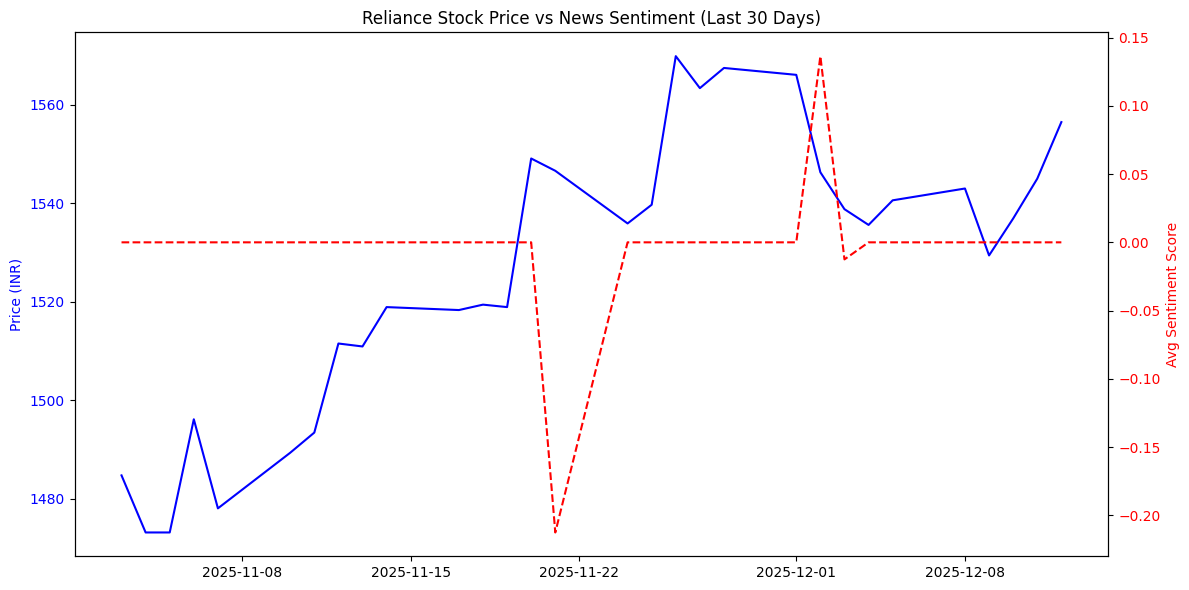

In [16]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12,6))

ax1.plot(merged['Date'], merged['Close'], color='blue', label='Stock Price')
ax1.set_ylabel("Price (INR)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(merged['Date'], merged['avg_sentiment'], color='red', label='Avg Sentiment', linestyle='--')
ax2.set_ylabel("Avg Sentiment Score", color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title("Reliance Stock Price vs News Sentiment (Last 30 Days)")
fig.tight_layout()
plt.show()


Next Step (Day 4): Extend this for multiple stocks


In [17]:
stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS"]  # example


In [18]:
import yfinance as yf
import pandas as pd

stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS"]
stock_data = yf.download(stocks, period="90d")

# Flatten MultiIndex columns
stock_data.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in stock_data.columns]

# Reset index
stock_data = stock_data.reset_index()

# Rename columns for convenience
stock_data.rename(columns={'Date_':'Date', 'Close_RELIANCE.NS':'Close_RELIANCE',
                           'Close_TCS.NS':'Close_TCS', 'Close_INFY.NS':'Close_INFY'}, inplace=True)

# Convert Date to datetime
stock_data['Date'] = pd.to_datetime(stock_data['Date'])
print(stock_data.head())


/tmp/ipykernel_69764/1677182431.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(stocks, period="90d")
[*********************100%***********************]  3 of 3 completed

        Date   Close_INFY  Close_RELIANCE    Close_TCS  High_INFY.NS  \
0 2025-08-05  1438.281616     1386.163696  3052.515137   1456.404084   
1 2025-08-06  1415.037354     1387.259521  3021.032471   1434.144864   
2 2025-08-07  1415.234375     1383.872925  3035.677979   1420.257453   
3 2025-08-08  1401.642456     1362.358887  3025.117188   1411.590144   
4 2025-08-11  1406.665527     1380.685669  3029.500977   1411.787194   

   High_RELIANCE.NS  High_TCS.NS  Low_INFY.NS  Low_RELIANCE.NS   Low_TCS.NS  \
0       1405.386969  3066.064699  1433.061482      1382.578042  3030.696610   
1       1390.347165  3055.404274  1408.733949      1377.797312  3014.755832   
2       1388.155746  3040.260983  1392.876575      1360.565987  2999.712021   
3       1391.641835  3048.430383  1395.732924      1359.569977  3013.759645   
4       1382.478557  3038.567017  1392.679683      1355.785119  3010.073435   

   Open_INFY.NS  Open_RELIANCE.NS  Open_TCS.NS  Volume_INFY.NS  \
0   1456.404084       1405

In [19]:
# df_news has 'pubDate' and 'sentiment_score'
df_news['pubDate'] = pd.to_datetime(df_news['pubDate'])

# Weekly sentiment index
weekly_sentiment = df_news.groupby(pd.Grouper(key='pubDate', freq='W'))['sentiment_score'].mean().reset_index()
weekly_sentiment.rename(columns={'pubDate':'Date', 'sentiment_score':'avg_sentiment'}, inplace=True)

print(weekly_sentiment.head())


        Date  avg_sentiment
0 2025-11-23      -0.106250
1 2025-11-30       0.000000
2 2025-12-07       0.037121
3 2025-12-14       0.000000


In [20]:
merged = pd.merge(stock_data[['Date','Close_RELIANCE']], weekly_sentiment, on='Date', how='left')
merged = merged.fillna(0)  # fill missing sentiment

print(merged.head())


        Date  Close_RELIANCE  avg_sentiment
0 2025-08-05     1386.163696            0.0
1 2025-08-06     1387.259521            0.0
2 2025-08-07     1383.872925            0.0
3 2025-08-08     1362.358887            0.0
4 2025-08-11     1380.685669            0.0


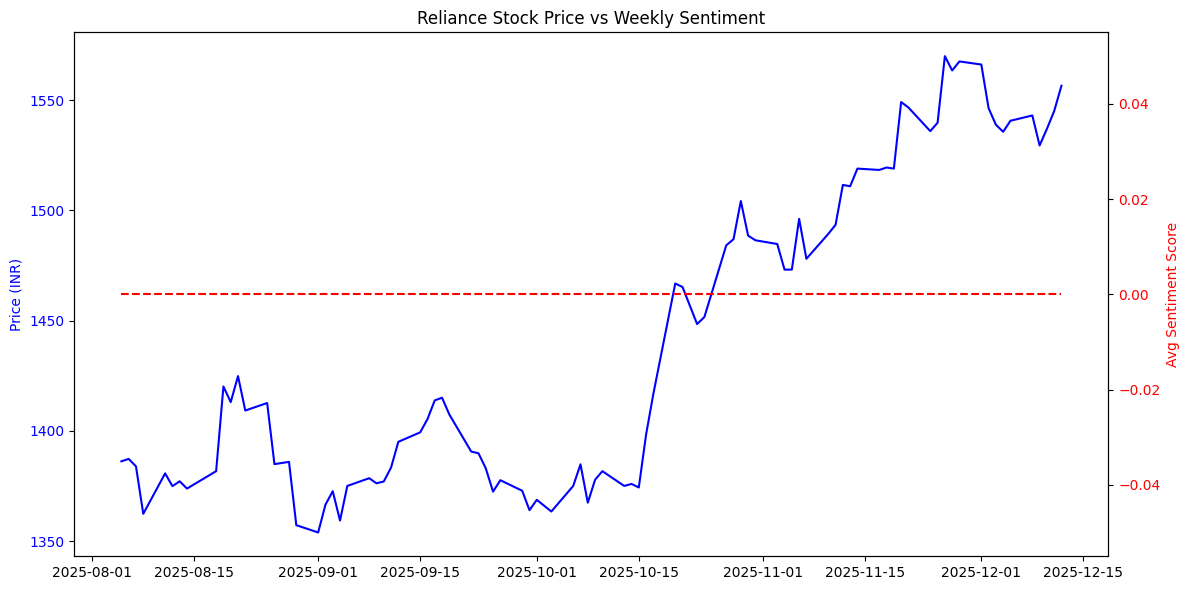

In [21]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12,6))

ax1.plot(merged['Date'], merged['Close_RELIANCE'], color='blue', label='Reliance Price')
ax1.set_ylabel("Price (INR)", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(merged['Date'], merged['avg_sentiment'], color='red', linestyle='--', label='Weekly Sentiment')
ax2.set_ylabel("Avg Sentiment Score", color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title("Reliance Stock Price vs Weekly Sentiment")
fig.tight_layout()
plt.show()



In [22]:
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv())

True

In [23]:
from openai import OpenAI
client = OpenAI()

summary_prompt = f"""
Weekly sentiment index for Reliance (last 3 months):
{weekly_sentiment.to_dict(orient='records')}

Provide a simple 2–3 line summary of the trend for a business report.
"""

response = client.chat.completions.create(
    model="gpt-5-mini",
    messages=[{"role":"user","content":summary_prompt}]
)

print(response.choices[0].message.content)


Sentiment for Reliance moved from a modest negative in the week of Nov 23 (−0.106) to neutral by Nov 30 and slightly positive on Dec 7 (+0.037). By Dec 14 it returned to neutral (0.0), indicating a short-lived uptick and an overall flattened, broadly neutral sentiment with limited momentum for a sustained positive trend.


/tmp/ipykernel_69764/1574593742.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(stocks, period="90d")  # last 90 days
[*********************100%***********************]  3 of 3 completed

        Date   Close_INFY  Close_RELIANCE    Close_TCS  High_INFY.NS  \
0 2025-08-05  1438.281616     1386.163696  3052.515137   1456.404084   
1 2025-08-06  1415.037354     1387.259521  3021.032471   1434.144864   
2 2025-08-07  1415.234375     1383.872925  3035.677979   1420.257453   
3 2025-08-08  1401.642456     1362.358887  3025.117188   1411.590144   
4 2025-08-11  1406.665527     1380.685669  3029.500977   1411.787194   

   High_RELIANCE.NS  High_TCS.NS  Low_INFY.NS  Low_RELIANCE.NS   Low_TCS.NS  \
0       1405.386969  3066.064699  1433.061482      1382.578042  3030.696610   
1       1390.347165  3055.404274  1408.733949      1377.797312  3014.755832   
2       1388.155746  3040.260983  1392.876575      1360.565987  2999.712021   
3       1391.641835  3048.430383  1395.732924      1359.569977  3013.759645   
4       1382.478557  3038.567017  1392.679683      1355.785119  3010.073435   

   Open_INFY.NS  Open_RELIANCE.NS  Open_TCS.NS  Volume_INFY.NS  \
0   1456.404084       1405


/tmp/ipykernel_69764/1574593742.py:51: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sentiment = df_news.groupby(pd.Grouper(key='pubDate', freq='M'))['sentiment_score'].mean().reset_index()


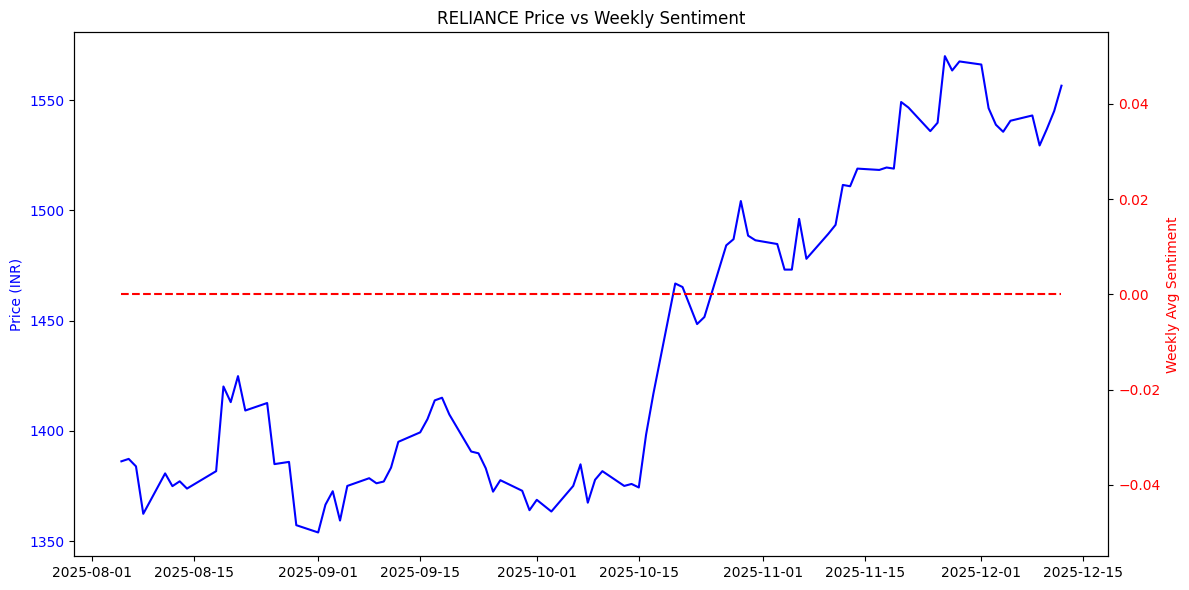

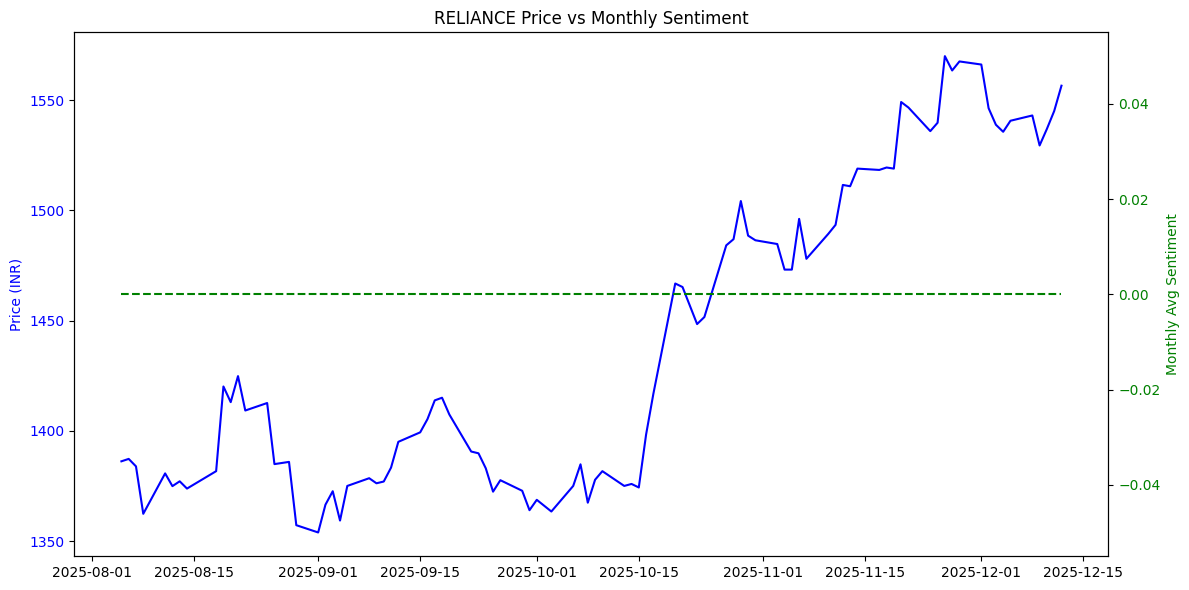

AI Summary for RELIANCE:
Reliance’s share price shows a clear uptrend, rising from about ₹1,386 in early August to ~₹1,556 by mid‑December (≈+12% gain), with the strongest acceleration in late October–November (peaking ~₹1,570). The weekly sentiment index is flat at 0.0 throughout, so no sentiment signal accompanies the price rise.
--------------------------------------------------


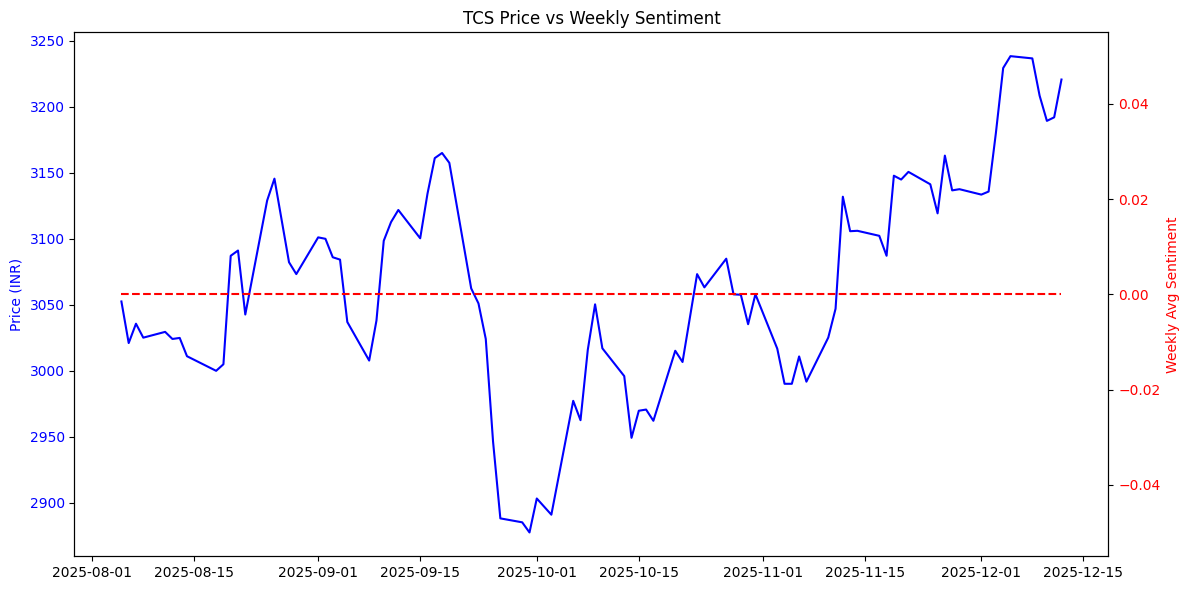

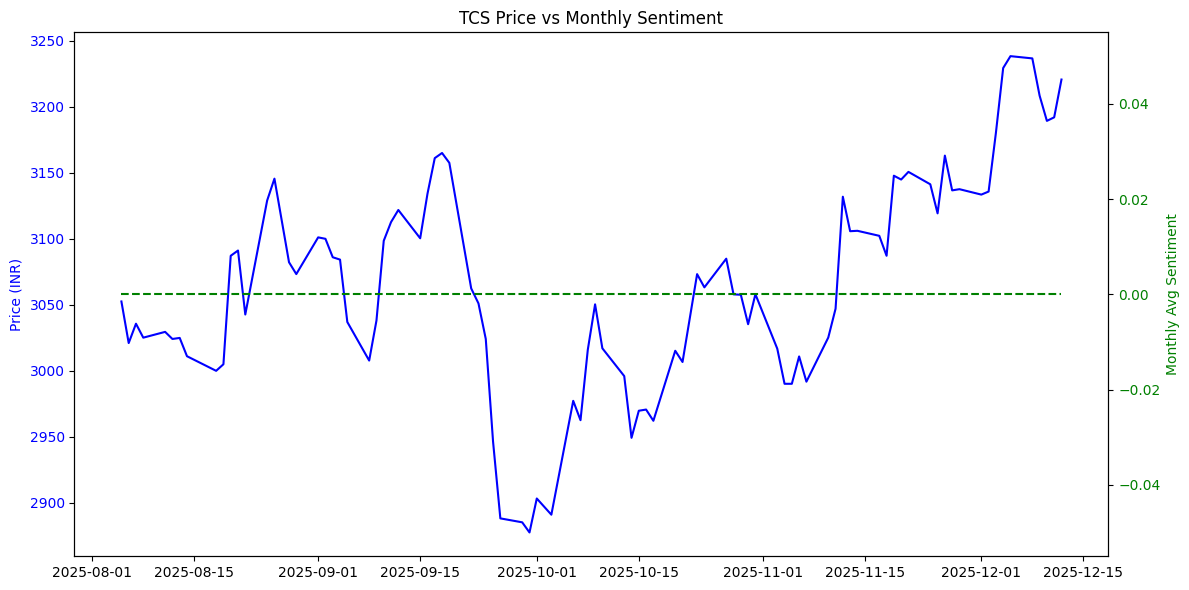

AI Summary for TCS:
TCS share price showed volatility: after a mid‑September peak near 3,165 it plunged to a late‑September low around 2,878, then staged a steady recovery through October–November. The rally accelerated into early December, reaching a fresh high ~3,238 (roughly +6% vs. the August level). Note: the weekly sentiment metric is zero throughout, so no sentiment signal is available.
--------------------------------------------------


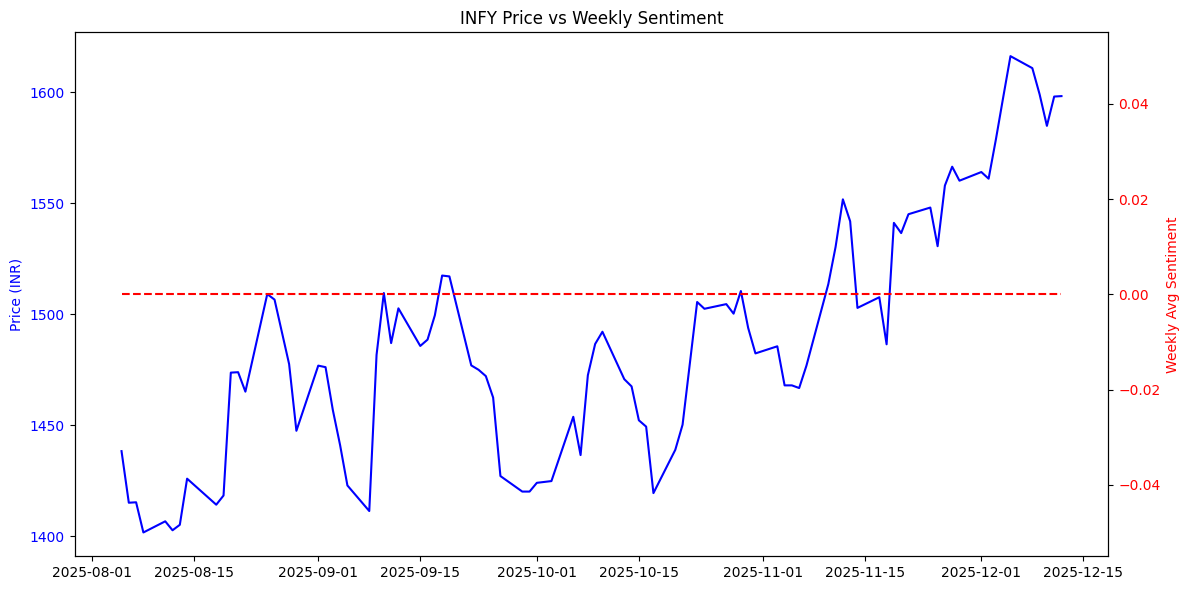

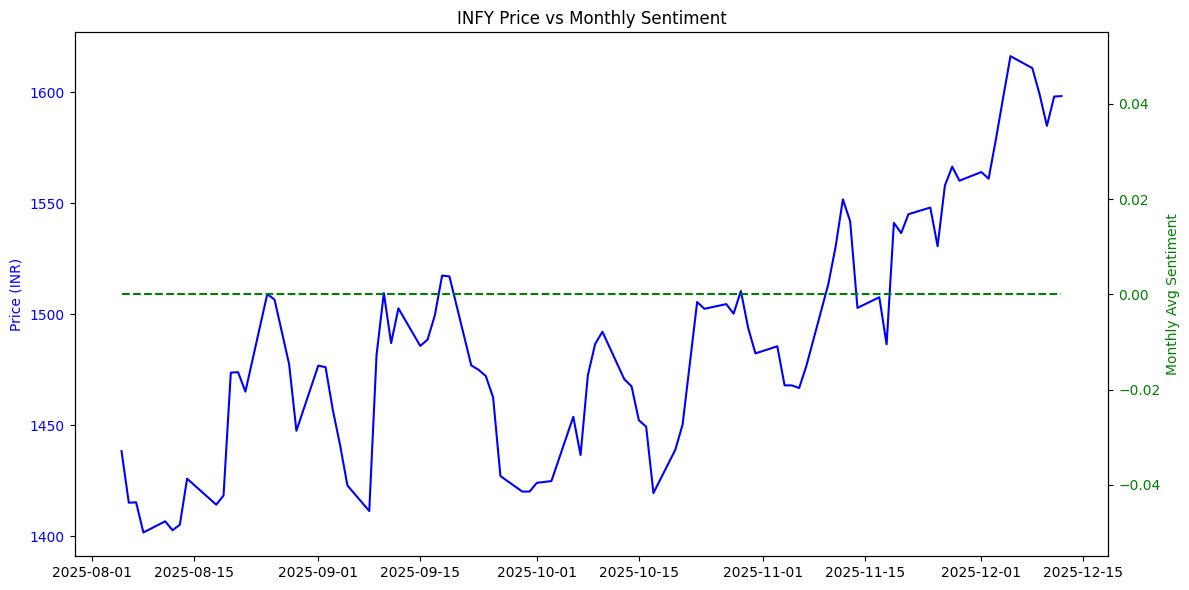

AI Summary for INFY:
INFY showed a clear upward trend over the past three months, rising from roughly ₹1,440 in early August to about ₹1,600 by mid‑December (≈11% gain), with intermittent pullbacks (notably to ~₹1,420 in late Sep/early Oct) and highs in mid‑Sep and late Nov/early Dec.  
The weekly sentiment index is flat at 0.0 throughout the period, suggesting no recorded sentiment signal—price moves appear driven by fundamentals or market/technical factors rather than the provided sentiment metric.
--------------------------------------------------


In [24]:
# ===============================================
# Market Sentiment Analysis + Stock Price Dashboard
# ===============================================

# Step 0: Install dependencies
# !pip install yfinance openai pandas matplotlib

# -----------------------------------------------
# Step 1: Imports
# -----------------------------------------------
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI

# -----------------------------------------------
# Step 2: Define stocks & download price data
# -----------------------------------------------
stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS"]  # Add more tickers if needed
stock_data = yf.download(stocks, period="90d")  # last 90 days

# Flatten MultiIndex columns
stock_data.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in stock_data.columns]
stock_data = stock_data.reset_index()
stock_data['Date'] = pd.to_datetime(stock_data['Date'])

# Rename Close columns for convenience
for stock in stocks:
    stock_data.rename(columns={f'Close_{stock}': f'Close_{stock.split(".")[0]}'}, inplace=True)

print(stock_data.head())

# -----------------------------------------------
# Step 3: Prepare news DataFrame (df_news)
# df_news must contain: 'pubDate', 'sentiment_score'
# -----------------------------------------------
# Example structure:
# df_news = pd.DataFrame({
#     'pubDate': ['2025-08-01', '2025-08-02', ...],
#     'sentiment_score': [0.1, -0.2, ...],
#     'stock': ['RELIANCE', 'TCS', ...]  # optional if multiple stocks
# })
df_news['pubDate'] = pd.to_datetime(df_news['pubDate'])

# -----------------------------------------------
# Step 4: Compute weekly & monthly sentiment
# -----------------------------------------------
weekly_sentiment = df_news.groupby(pd.Grouper(key='pubDate', freq='W'))['sentiment_score'].mean().reset_index()
weekly_sentiment.rename(columns={'pubDate':'Date', 'sentiment_score':'avg_sentiment_weekly'}, inplace=True)

monthly_sentiment = df_news.groupby(pd.Grouper(key='pubDate', freq='M'))['sentiment_score'].mean().reset_index()
monthly_sentiment.rename(columns={'pubDate':'Date', 'sentiment_score':'avg_sentiment_monthly'}, inplace=True)

# -----------------------------------------------
# Step 5: Merge stock data with weekly & monthly sentiment
# -----------------------------------------------
def merge_stock_sentiment(stock_name):
    merged_weekly = pd.merge(stock_data[['Date', f'Close_{stock_name}']], 
                             weekly_sentiment, on='Date', how='left').fillna(0)
    merged_monthly = pd.merge(stock_data[['Date', f'Close_{stock_name}']], 
                              monthly_sentiment, on='Date', how='left').fillna(0)
    return merged_weekly, merged_monthly

# -----------------------------------------------
# Step 6: Plot function
# -----------------------------------------------
def plot_stock_sentiment(stock_name, merged_weekly, merged_monthly):
    # Weekly plot
    fig, ax1 = plt.subplots(figsize=(12,6))
    ax1.plot(merged_weekly['Date'], merged_weekly[f'Close_{stock_name}'], color='blue', label='Price')
    ax1.set_ylabel("Price (INR)", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    ax2 = ax1.twinx()
    ax2.plot(merged_weekly['Date'], merged_weekly['avg_sentiment_weekly'], color='red', linestyle='--', label='Weekly Sentiment')
    ax2.set_ylabel("Weekly Avg Sentiment", color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    plt.title(f"{stock_name} Price vs Weekly Sentiment")
    fig.tight_layout()
    plt.show()

    # Monthly plot
    fig, ax1 = plt.subplots(figsize=(12,6))
    ax1.plot(merged_monthly['Date'], merged_monthly[f'Close_{stock_name}'], color='blue', label='Price')
    ax1.set_ylabel("Price (INR)", color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    ax2 = ax1.twinx()
    ax2.plot(merged_monthly['Date'], merged_monthly['avg_sentiment_monthly'], color='green', linestyle='--', label='Monthly Sentiment')
    ax2.set_ylabel("Monthly Avg Sentiment", color='green')
    ax2.tick_params(axis='y', labelcolor='green')

    plt.title(f"{stock_name} Price vs Monthly Sentiment")
    fig.tight_layout()
    plt.show()

# -----------------------------------------------
# Step 7: AI summary function
# -----------------------------------------------
def generate_ai_summary(sentiment_df, stock_name):
    client = OpenAI()
    prompt = f"""
    Weekly sentiment index for {stock_name} (last 3 months):
    {sentiment_df.to_dict(orient='records')}
    Provide a simple 2–3 line summary of the trend for a business report.
    """
    response = client.chat.completions.create(
        model="gpt-5-mini",
        messages=[{"role":"user","content":prompt}]
    )
    print(f"AI Summary for {stock_name}:")
    print(response.choices[0].message.content)
    print("-"*50)

# -----------------------------------------------
# Step 8: Run for all stocks
# -----------------------------------------------
for stock in [s.split('.')[0] for s in stocks]:
    merged_weekly, merged_monthly = merge_stock_sentiment(stock)
    plot_stock_sentiment(stock, merged_weekly, merged_monthly)
    generate_ai_summary(merged_weekly, stock)
